# Prescribed BVOC emissions, all 19 MEGAN-fed species: CTRL and LCC, PD and FUT
Forcing files of the fBVOC runs on the **new chain** (CO₂-fix spin-ups; 2001–2014 climatologies, `run_bvoc_climatology_array.sh`):

| Source | Case | Files read here | Used by |
|---|---|---|---|
| CTRL_PD | `NF2000…nudg_ctrl_f19_f19-20261029` | `ems_<case>_2001-2014_<VAR>.nc` (year 2000) | `LCC_PD_fBVOCctrlPD` (14b), `CTRL_PD_fBVOCctrlPD` (14c); relabelled to 2100 in `LCC_FUT_fBVOCctrlPD` (24b) |
| LCC_PD | `NF2000…nudg_lcc_f19_f19-20261028` | `ems_<case>_2001-2014_<VAR>.nc` (year 2000) | `LCC_PD_fBVOClccPD` (14e); relabelled to 2100 in `LCC_FUT_fBVOClccPD` (24d) |
| CTRL_FUT | `NF2100ssp585…nudg_ctrl_f19_f19-20261028` | `ems_<case>_2001-2014_on_yr2100_<VAR>.nc` | `LCC_FUT_fBVOCctrlFUT` (24c), `CTRL_FUT_fBVOCctrlFUT` (24e) |
| LCC_FUT | `NF2100ssp585…nudg_lcc_f19_f19-20261028` (emissions from the output-only rerun `LCC_FUT_HRBVOC`, merged) | `ems_<case>_2001-2014_on_yr2100_<VAR>.nc` | `LCC_FUT_fBVOClccFUT` (24g) |

The `_on_yr2100` files differ from the year-2000 files only in their dates, so columns compare **sources**, not years.
ISOP and MTERP come from `SF*` (MEGAN + biomass burning); the other 17 from `MEG_*` (MEGAN only). 8 species are half-hourly, 11 monthly (`MONTHLY_VARS`).
PNGs (200 dpi) saved in `plot_bvoc_emissions_outputs/`. These maps inspect the forcing files; they do not validate the fluxes applied by CAM. The ISOP/MTERP-only version of this notebook is in `prescribe-just-ISOP-MTERP/` (legacy, old chain).

In [1]:
from pathlib import Path
import calendar, sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

PREPROC = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/preprocess/bvoc-emissions")   # notebook moved to diagnostics/2_bvoc-emissions (2026-11-16)
sys.path.insert(0, str(PREPROC))   # species list, molar masses, names from the emission script
from create_bvoc_emissions_climatology_staged import MOLAR_MASS, MONTHLY_VARS, OUTPUT_VAR_NAME, AVOGADRO

DATA_DIR = Path("/cluster/shared/noresm/inputdata/atm/cam/prescribed_data/bvoc_emissions")
# Keep up to date with the CTRL/LCC versions (CLAUDE.md "When a run version changes"). New chain (CO2-fix spin-ups).
SOURCES = {"CTRL_PD": "ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029_2001-2014",
           "LCC_PD": "ems_NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014",
           "CTRL_FUT": "ems_NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028_2001-2014_on_yr2100",
           "LCC_FUT": "ems_NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014_on_yr2100"}
# Project palette (src/boreal_forest_expansion/plotting/palette.py), in order; LCC lines dashed
COLORS = {"CTRL_PD": "#5D9A92", "LCC_PD": "#2C3990", "CTRL_FUT": "#DE7A3A", "LCC_FUT": "#BC423E"}
STYLES = {"CTRL_PD": "-", "LCC_PD": "--", "CTRL_FUT": "-", "LCC_FUT": "--"}
SPECIES = list(MOLAR_MASS)            # history-field names: SFISOP, SFMTERP, MEG_BCARY, ...
MASK_FILE = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-modified-cells/modified_cells.nc")
MDAYS = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], float)
SEASONS = {"DJF": (12, 1, 2), "MAM": (3, 4, 5), "JJA": (6, 7, 8), "SON": (9, 10, 11)}
CHUNK = 48 * 7                        # half-hourly records read per step (one week)
OUTDIR = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/2_bvoc-emissions/plot_bvoc_emissions_outputs")   # saved figures
OUTDIR.mkdir(exist_ok=True)

def save(fig, name):
    """PNG (200 dpi) in OUTDIR, then show."""
    fig.savefig(OUTDIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. One pass per file
Annual and seasonal mean maps, and area-weighted series (global, north of 45°N, modified cells). Half-hourly files are read one week at a time; their annual mean is the mean of all 17520 records. Monthly files are averaged with month-length weights. Seasonal means of half-hourly files weight every record equally, so they are also day-weighted.

In [2]:
with xr.open_dataset(MASK_FILE) as ds:
    mask = ds["modified"].load().astype(bool)
first = xr.open_dataset(DATA_DIR / f"{SOURCES['CTRL_PD']}_SFISOP.nc", decode_times=False)
lat, lon = first.lat, first.lon
for name, a, b in (("lat", mask.lat.values, lat.values), ("lon", mask.lon.values % 360, lon.values % 360)):
    if a.shape != b.shape or np.abs(a - b).max() > 1e-5:   # require the same grid; never remap silently
        raise ValueError(f"mask and emission {name} differ")
mask = mask.assign_coords(lat=lat, lon=lon)
coslat = np.cos(np.deg2rad(lat)) * xr.ones_like(lon)
AREA = coslat / float(coslat.sum()) * 4 * np.pi * 6.371e6**2          # m2 per cell
REGIONS = {"global": coslat, ">45N": coslat.where(lat > 45, 0), "modified": coslat.where(mask, 0)}

def to_tg_per_yr(field, var, weights):
    """molecules/cm2/s -> Tg(species)/yr over the cells with nonzero weight."""
    kg = field / (AVOGADRO / MOLAR_MASS[var] * 1e-4)
    return float((kg * AREA).where(weights > 0, 0).sum()) * 365 * 86400 / 1e9

annual, seasonal, series, units = {}, {}, {}, {}
for var in SPECIES:
    name, monthly = OUTPUT_VAR_NAME[var], var in MONTHLY_VARS
    for src, prefix in SOURCES.items():
        path = DATA_DIR / f"{prefix}_{var}.nc"
        print(f"Reading {path.name}", flush=True)
        with xr.open_dataset(path, decode_times=False) as ds:
            units[var] = ds[name].attrs.get("units", "?")
            dates = ds["date"].values.astype(int)
            months = (dates // 100) % 100
            if monthly:
                x = ds[name].load()
                annual[var, src] = x.weighted(xr.DataArray(MDAYS, dims="time")).mean("time")
                seasonal[var, src] = {s: x.isel(time=np.flatnonzero(np.isin(months, m)))
                                       .weighted(xr.DataArray(MDAYS[np.array(m) - 1], dims="time")).mean("time")
                                      for s, m in SEASONS.items()}
                xpos = np.arange(1, 13) + 0.5                      # mid-month on the month axis
                series[var, src] = {r: pd.Series(x.weighted(w).mean(("lat", "lon")).values, index=xpos)
                                    for r, w in REGIONS.items()}
            else:
                total, sums, counts, regional = 0, {}, {}, {r: [] for r in REGIONS}
                for start in range(0, len(dates), CHUNK):
                    x = ds[name].isel(time=slice(start, start + CHUNK)).load()
                    total = total + x.sum("time")
                    for s, m in SEASONS.items():
                        idx = np.flatnonzero(np.isin(months[start:start + CHUNK], m))
                        if len(idx):
                            sums[s] = sums.get(s, 0) + x.isel(time=idx).sum("time")
                            counts[s] = counts.get(s, 0) + len(idx)
                    for r, w in REGIONS.items():
                        regional[r].append(x.weighted(w).mean(("lat", "lon")).values)
                annual[var, src] = total / len(dates)
                seasonal[var, src] = {s: sums[s] / counts[s] for s in SEASONS}
                # daily means; dates of 1 Jan of the next year (last record, phase 1800 s) go to the right edge
                xd = ((dates // 100) % 100) + ((dates % 100) - 1) / MDAYS[((dates // 100) % 100) - 1]
                xd = xd + 12 * (dates // 10000 - dates[0] // 10000)
                series[var, src] = {r: pd.Series(np.concatenate(v)).groupby(xd).mean() for r, v in regional.items()}
first.close()

Reading ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029_2001-2014_SFISOP.nc
Reading ems_NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014_SFISOP.nc
Reading ems_NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028_2001-2014_on_yr2100_SFISOP.nc
Reading ems_NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014_on_yr2100_SFISOP.nc
Reading ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029_2001-2014_SFMTERP.nc
Reading ems_NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014_SFMTERP.nc
Reading ems_NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028_2001-2014_on_yr2100_SFMTERP.nc
Reading ems_NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014_on_yr2100_SFMTERP.nc
Reading ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029_2001-2014_MEG_BCARY.nc
Reading ems_NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014_MEG_BCARY.nc
Reading ems_NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028_2001-2014_

## 2. Totals per species and region (Tg of species per year)
Cross-species comparison in one unit (molecules/cm²/s converted back with the CAM molar mass). *modified* = LCC-modified cells (1161 cells, 46–82°N).
Columns per region: the four sources; **FUT/PD** = CTRL_FUT / CTRL_PD (climate background); **LCC−CTRL PD %** and **LCC−CTRL FUT %** = forest-expansion change in % of the CTRL source of the same period.

In [3]:
rows = []
for var in SPECIES:
    row = {"species": OUTPUT_VAR_NAME[var], "field": var, "sampling": "monthly" if var in MONTHLY_VARS else "30 min"}
    for r, w in REGIONS.items():
        tg = {s: to_tg_per_yr(annual[var, s], var, w) for s in SOURCES}
        for s in SOURCES:
            row[f"{r} {s}"] = tg[s]
        row[f"{r} FUT/PD"] = tg["CTRL_FUT"] / tg["CTRL_PD"] if tg["CTRL_PD"] else np.nan
        for p in ("PD", "FUT"):
            row[f"{r} LCC−CTRL {p} %"] = 100 * (tg[f"LCC_{p}"] / tg[f"CTRL_{p}"] - 1) if tg[f"CTRL_{p}"] else np.nan
    rows.append(row)
totals = pd.DataFrame(rows).set_index("species")
totals.to_csv(PREPROC / "bvoc_totals_tg_per_yr.csv")   # read by preprocess/bvoc-emissions/bvoc_species_processes.ipynb
for r in REGIONS:
    print(f"\n{r} (Tg/yr)")
    sub = totals[["sampling"] + [c for c in totals.columns if c.startswith(f"{r} ")]]
    with pd.option_context("display.float_format", "{:.3g}".format, "display.width", 200):
        display(sub.rename(columns=lambda c: c.removeprefix(f"{r} ")))


global (Tg/yr)


,sampling,CTRL_PD,LCC_PD,CTRL_FUT,LCC_FUT,FUT/PD,LCC−CTRL PD %,LCC−CTRL FUT %
species,,,,,,,,
ISOP,30 min,510,510,886,888,1.74,-0.0897,0.242
MTERP,30 min,145,144,511,511,3.53,-0.109,0.146
BCARY,30 min,13.3,13.3,56.9,56.9,4.27,-0.19,0.0334
C3H6,30 min,16.1,16,45.9,45.7,2.85,-0.26,-0.3
BIGENE,30 min,8.04,8.02,22.9,22.9,2.85,-0.26,-0.3
CH3CHO,30 min,18.8,18.8,72,72.1,3.83,-0.115,0.143
CH2O,30 min,4.54,4.53,16.3,16.3,3.59,-0.14,0.012
C2H4,30 min,27,27,85.2,85,3.16,-0.184,-0.191
CH3OH,monthly,104,104,297,297,2.86,-0.101,-0.247



>45N (Tg/yr)


,sampling,CTRL_PD,LCC_PD,CTRL_FUT,LCC_FUT,FUT/PD,LCC−CTRL PD %,LCC−CTRL FUT %
species,,,,,,,,
ISOP,30 min,9.36,9.65,23.2,23.6,2.48,3.06,1.67
MTERP,30 min,8.34,8.4,35.2,35.1,4.22,0.702,-0.264
BCARY,30 min,0.529,0.526,3.35,3.29,6.33,-0.482,-1.65
C3H6,30 min,1.15,1.13,4.01,3.85,3.48,-1.73,-4.11
BIGENE,30 min,0.577,0.567,2.01,1.92,3.48,-1.73,-4.11
CH3CHO,30 min,0.74,0.747,3.91,3.89,5.28,0.854,-0.304
CH2O,30 min,0.2,0.2,0.961,0.943,4.79,-0.148,-1.83
C2H4,30 min,1.47,1.45,5.92,5.7,4.02,-1.26,-3.76
CH3OH,monthly,9.3,9.26,32.7,31.9,3.52,-0.442,-2.51



modified (Tg/yr)


,sampling,CTRL_PD,LCC_PD,CTRL_FUT,LCC_FUT,FUT/PD,LCC−CTRL PD %,LCC−CTRL FUT %
species,,,,,,,,
ISOP,30 min,4.13,4.37,12.5,12.9,3.03,5.83,2.9
MTERP,30 min,4.98,5.01,22.6,22.5,4.54,0.706,-0.527
BCARY,30 min,0.291,0.287,2.07,2.01,7.1,-1.51,-2.8
C3H6,30 min,0.5,0.476,2.19,2.02,4.38,-4.72,-7.7
BIGENE,30 min,0.25,0.238,1.1,1.01,4.38,-4.72,-7.7
CH3CHO,30 min,0.385,0.389,2.37,2.35,6.15,0.927,-0.649
CH2O,30 min,0.0879,0.0867,0.535,0.516,6.08,-1.35,-3.49
C2H4,30 min,0.556,0.531,3.02,2.79,5.44,-4.52,-7.61
CH3OH,monthly,3.68,3.6,17.7,16.8,4.8,-2.14,-4.84


## 3. Annual-mean maps: CTRL_PD, CTRL_FUT, FUT − PD
Climate-background change of the CTRL sources. One row per species, each with its own colour scale (PD and FUT share it). Split into half-hourly and monthly species. The forest-expansion change (LCC − CTRL) is in section 5.

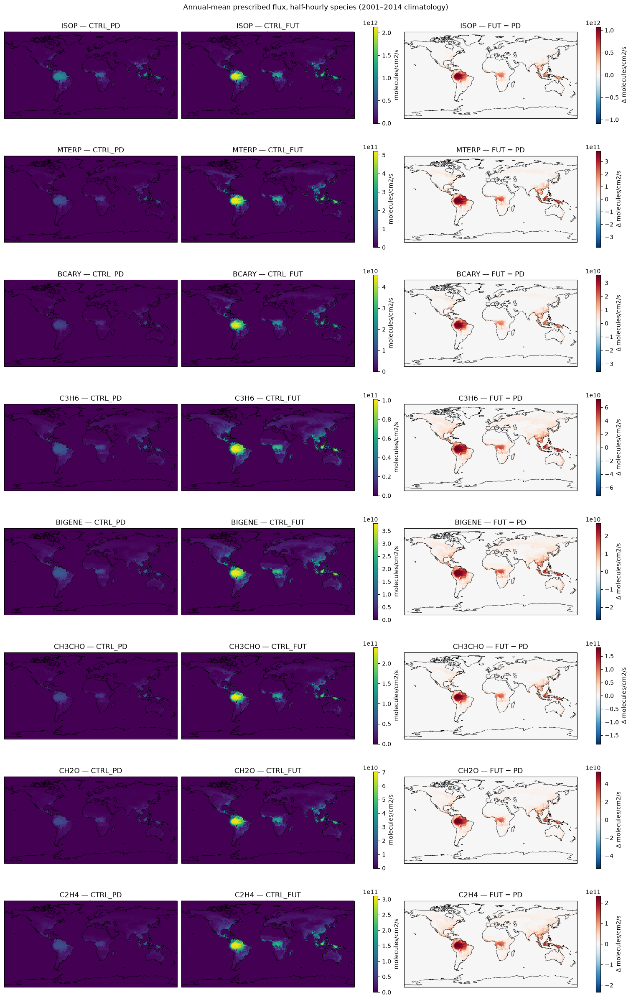

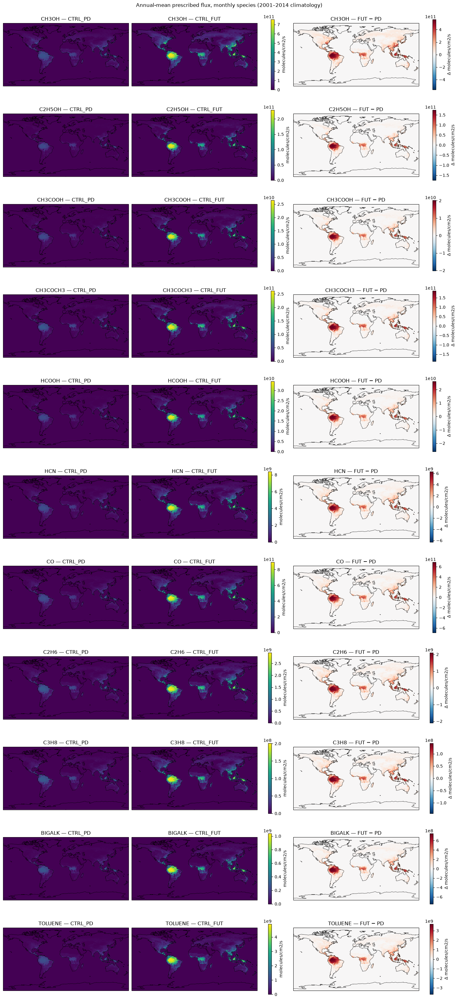

In [4]:
CIRCLE = mpath.Path(np.column_stack([np.sin(t := np.linspace(0, 2 * np.pi, 100)), np.cos(t)]) * 0.5 + 0.5)

def draw(ax, field, extent, **kw):
    values, lons = add_cyclic_point(field.values, coord=field.lon.values)
    mesh = ax.pcolormesh(lons, field.lat, values, transform=ccrs.PlateCarree(), shading="auto", **kw)
    if extent:
        ax.set_extent(extent, crs=ccrs.PlateCarree()); ax.set_boundary(CIRCLE, transform=ax.transAxes)
    else:
        ax.set_global()
    ax.coastlines(linewidth=0.5)
    return mesh

def plot_rows(vars_, title, name, extent=None):
    proj = ccrs.NorthPolarStereo() if extent else ccrs.PlateCarree()
    fig, axes = plt.subplots(len(vars_), 3, figsize=(15 if not extent else 11, 3 * len(vars_)),
                             subplot_kw={"projection": proj}, constrained_layout=True, squeeze=False)
    for row, var in zip(axes, vars_):
        pdf, fut = annual[var, "CTRL_PD"], annual[var, "CTRL_FUT"]
        if extent:
            pdf, fut = (f.where(f.lat > 45, drop=True) for f in (pdf, fut))
        diff = fut - pdf
        vmax = max(float(pdf.max()), float(fut.max()), 1e-30)
        dmax = max(float(abs(diff).max()), 1e-30)
        for ax, field, kw, label in ((row[0], pdf, dict(cmap="viridis", vmin=0, vmax=vmax), "CTRL_PD"),
                                     (row[1], fut, dict(cmap="viridis", vmin=0, vmax=vmax), "CTRL_FUT"),
                                     (row[2], diff, dict(cmap="RdBu_r", norm=TwoSlopeNorm(0, -dmax, dmax)), "FUT − PD")):
            mesh = draw(ax, field, extent, **kw)
            ax.set_title(f"{OUTPUT_VAR_NAME[var]} — {label}")
            if label != "CTRL_PD":
                fig.colorbar(mesh, ax=ax, shrink=0.8, label=units[var] if label == "CTRL_FUT" else f"Δ {units[var]}")
    fig.suptitle(title)
    save(fig, name)

HALF_HOURLY = [v for v in SPECIES if v not in MONTHLY_VARS]
MONTHLY = [v for v in SPECIES if v in MONTHLY_VARS]
plot_rows(HALF_HOURLY, "Annual-mean prescribed flux, half-hourly species (2001–2014 climatology)", "annual_ctrl_pd_fut_global_halfhourly")
plot_rows(MONTHLY, "Annual-mean prescribed flux, monthly species (2001–2014 climatology)", "annual_ctrl_pd_fut_global_monthly")

## 4. North of 45°N (forest-expansion region)
Same layout as section 3, polar stereographic.

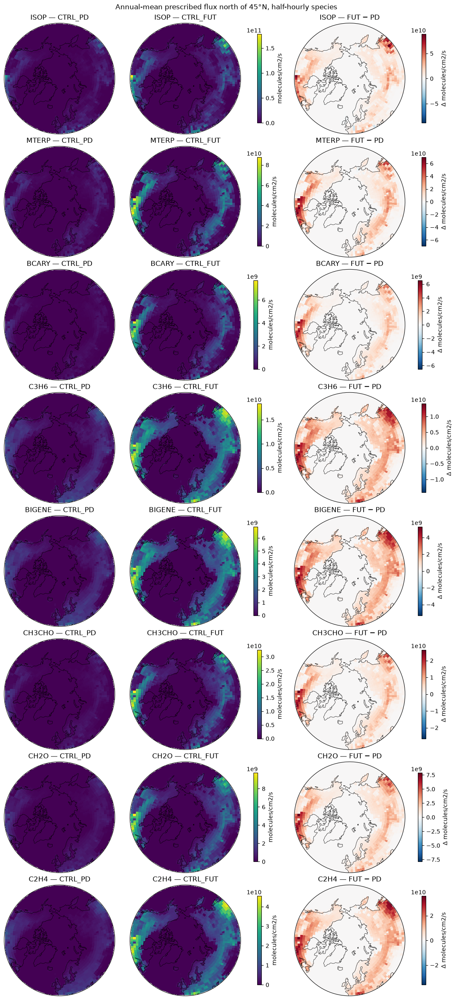

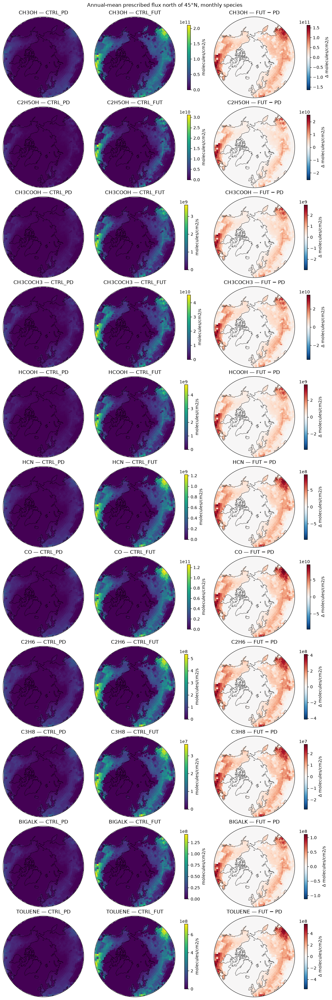

In [5]:
plot_rows(HALF_HOURLY, "Annual-mean prescribed flux north of 45°N, half-hourly species", "annual_ctrl_pd_fut_45N_halfhourly", extent=[-180, 180, 45, 90])
plot_rows(MONTHLY, "Annual-mean prescribed flux north of 45°N, monthly species", "annual_ctrl_pd_fut_45N_monthly", extent=[-180, 180, 45, 90])

## 5. Forest-expansion change north of 45°N: LCC − CTRL, PD and FUT
Annual-mean LCC − CTRL per period; PD and FUT share one symmetric scale per species. Black line: LCC-modified cells.

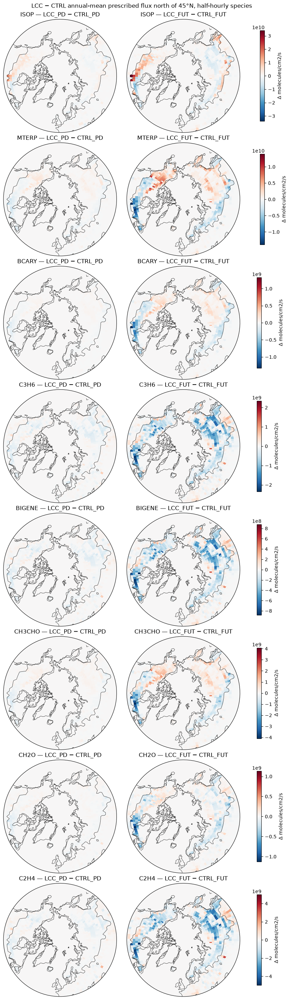

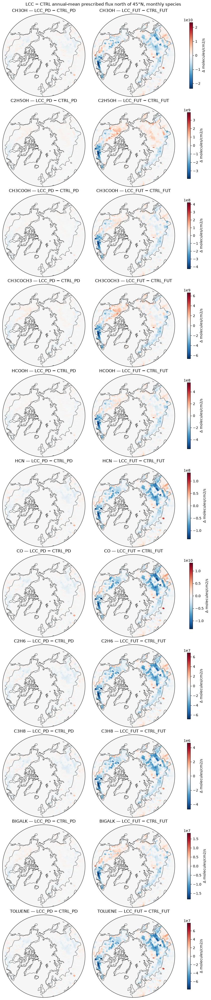

In [6]:
def plot_lcc_rows(vars_, title, name, extent=(-180, 180, 45, 90)):
    fig, axes = plt.subplots(len(vars_), 2, figsize=(8.5, 3.6 * len(vars_)),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True, squeeze=False)
    m = mask.where(lat > 45, drop=True).astype(float)
    mvals, mlons = add_cyclic_point(m.values, coord=m.lon.values)
    for row, var in zip(axes, vars_):
        diffs = {p: (annual[var, f"LCC_{p}"] - annual[var, f"CTRL_{p}"]).where(lat > 45, drop=True) for p in ("PD", "FUT")}
        dmax = max(max(float(abs(d).max()) for d in diffs.values()), 1e-30)
        for ax, (p, d) in zip(row, diffs.items()):
            mesh = draw(ax, d, list(extent), cmap="RdBu_r", norm=TwoSlopeNorm(0, -dmax, dmax))
            ax.contour(mlons, m.lat, mvals, levels=[0.5], colors="k", linewidths=0.5, transform=ccrs.PlateCarree())
            ax.set_title(f"{OUTPUT_VAR_NAME[var]} — LCC_{p} − CTRL_{p}")
        fig.colorbar(mesh, ax=row.tolist(), shrink=0.8, label=f"Δ {units[var]}")
    fig.suptitle(title)
    save(fig, name)

plot_lcc_rows(HALF_HOURLY, "LCC − CTRL annual-mean prescribed flux north of 45°N, half-hourly species", "annual_lcc_minus_ctrl_45N_halfhourly")
plot_lcc_rows(MONTHLY, "LCC − CTRL annual-mean prescribed flux north of 45°N, monthly species", "annual_lcc_minus_ctrl_45N_monthly")

## 6. Seasonal cycles: global and modified cells
Area-weighted means; daily means for half-hourly species, monthly values (markers) for monthly species. Units per panel. CTRL solid, LCC dashed.

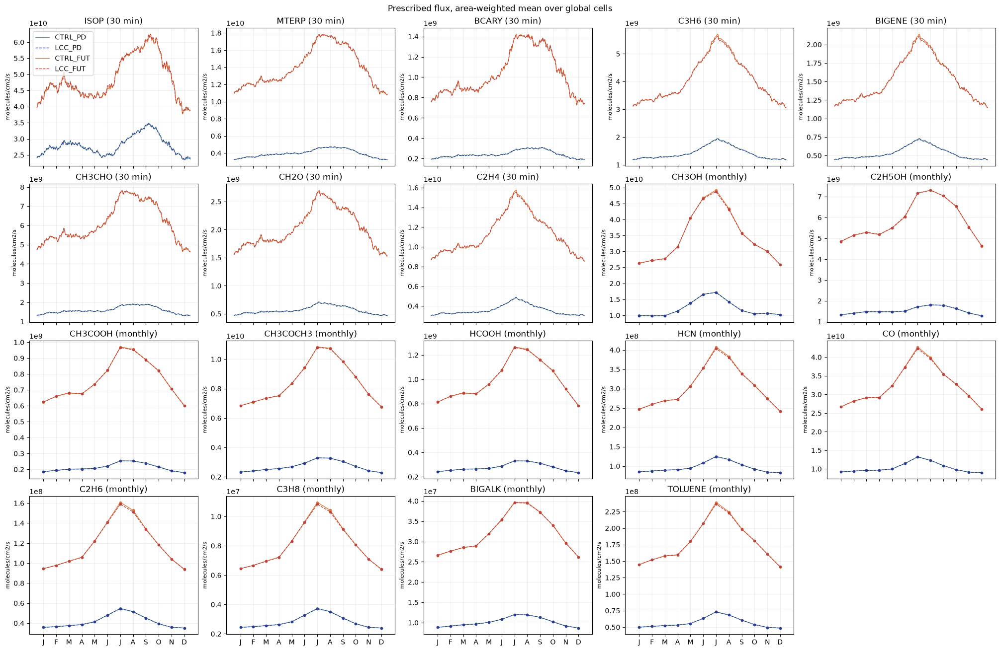

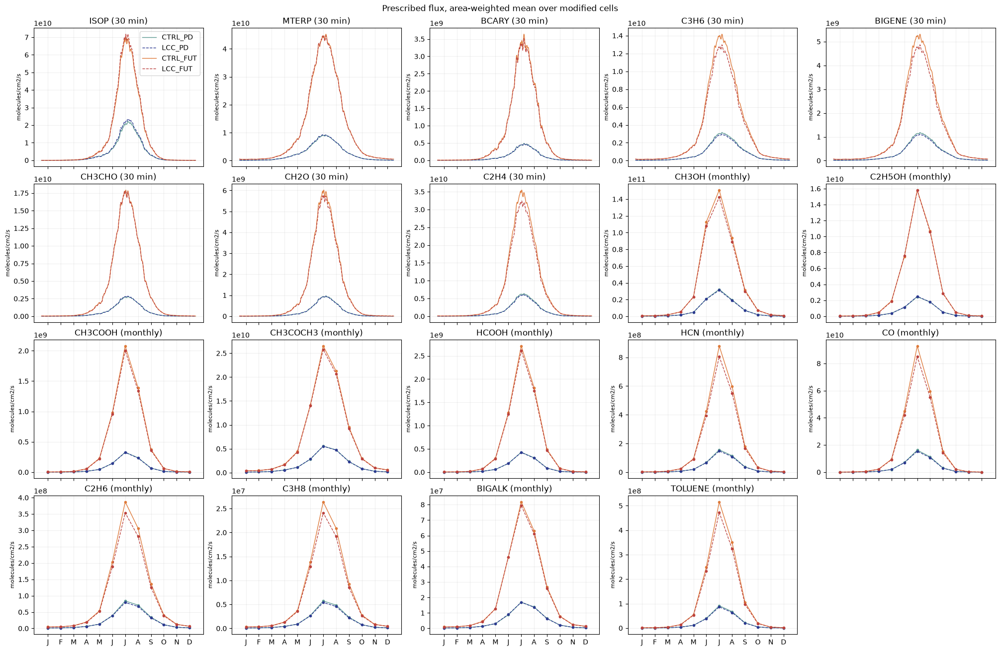

In [7]:
for region in ("global", "modified"):
    fig, axes = plt.subplots(4, 5, figsize=(20, 13), sharex=True, constrained_layout=True)
    for ax, var in zip(axes.flat, SPECIES):
        for src in SOURCES:
            s = series[var, src][region]
            ax.plot(s.index, s.values, color=COLORS[src], linestyle=STYLES[src], label=src, linewidth=1,
                    marker="o" if var in MONTHLY_VARS else None, markersize=3)
        ax.set_title(f"{OUTPUT_VAR_NAME[var]} ({'monthly' if var in MONTHLY_VARS else '30 min'})")
        ax.set_ylabel(units[var], fontsize=8)
        ax.set_xticks(np.arange(1, 13) + 0.5, [m[0] for m in calendar.month_abbr[1:]])
        ax.grid(alpha=0.2)
    axes.flat[-1].axis("off")
    axes.flat[0].legend()
    fig.suptitle(f"Prescribed flux, area-weighted mean over {region} cells")
    save(fig, f"seasonal_cycle_{region}")

## 7. Seasonal maps north of 45°N (per species, all four sources)
Optional detail: set `SEASONAL_SPECIES` (history-field names) to look at more species. Cells with zero flux are white.

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

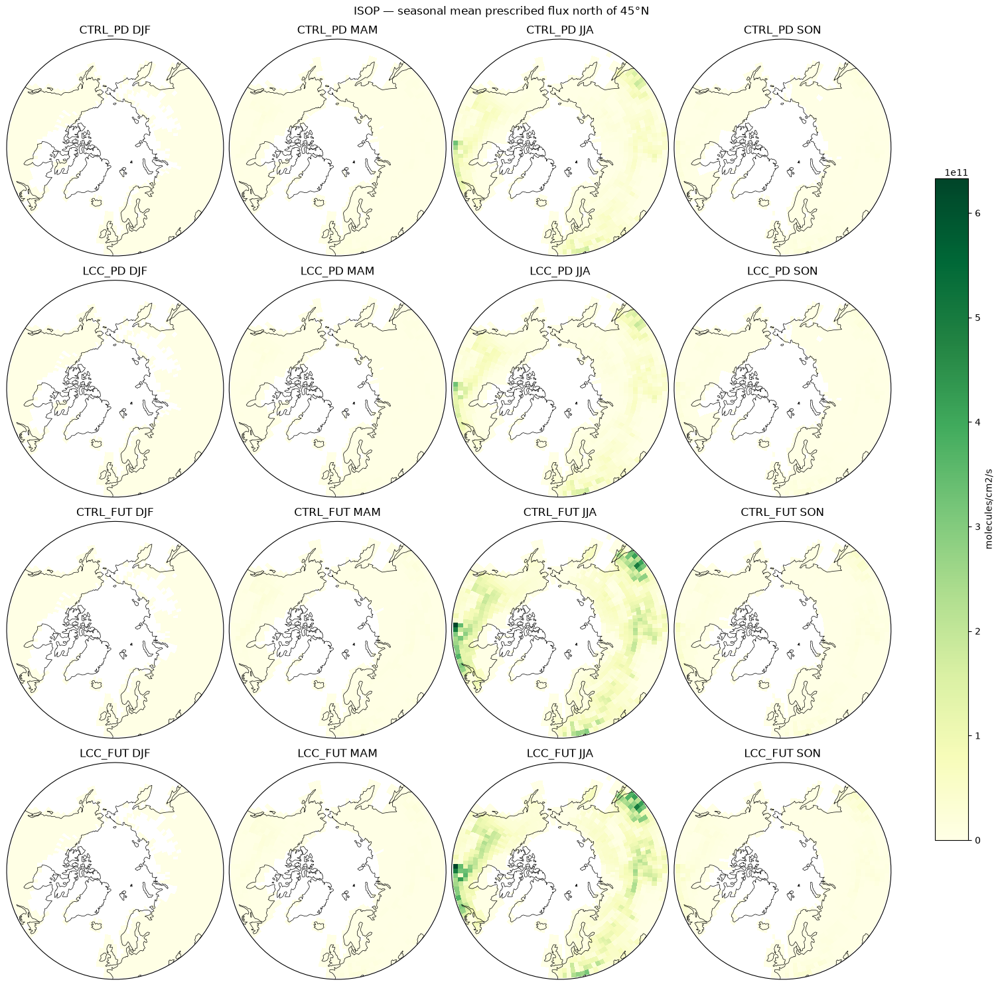

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

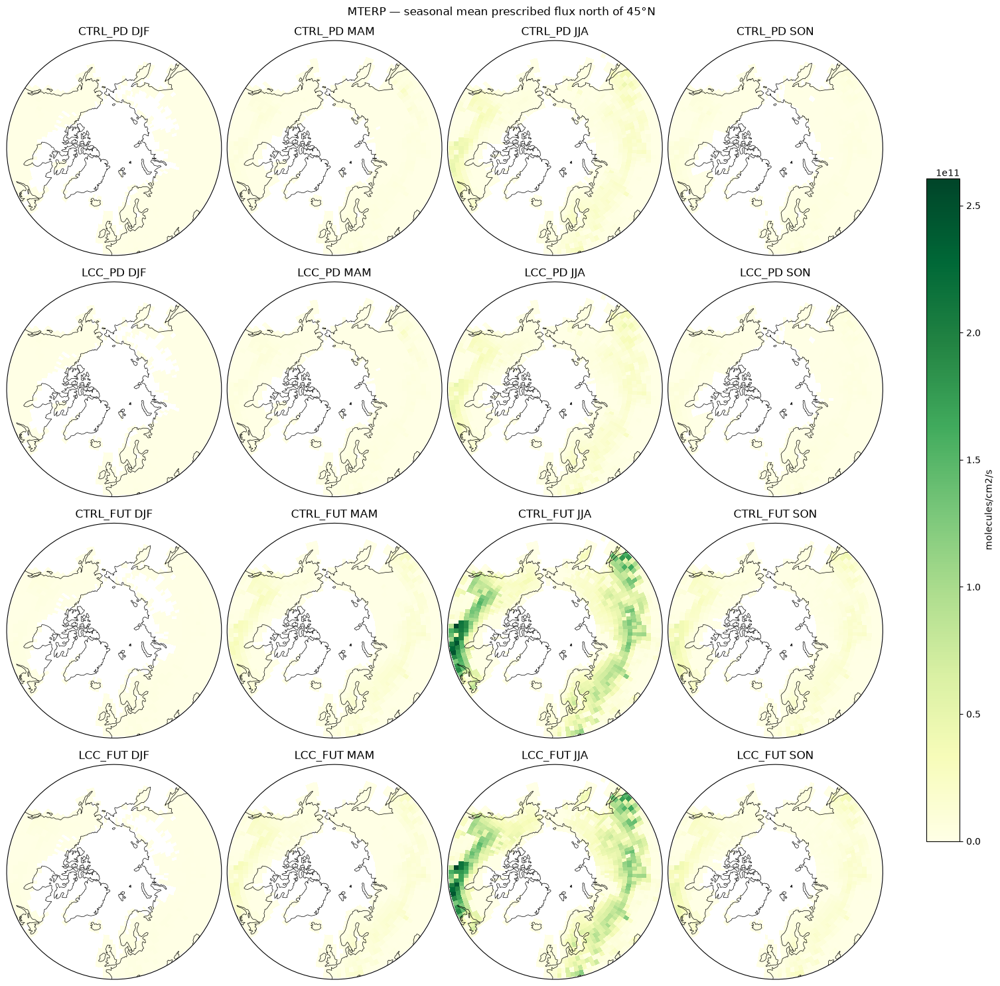

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

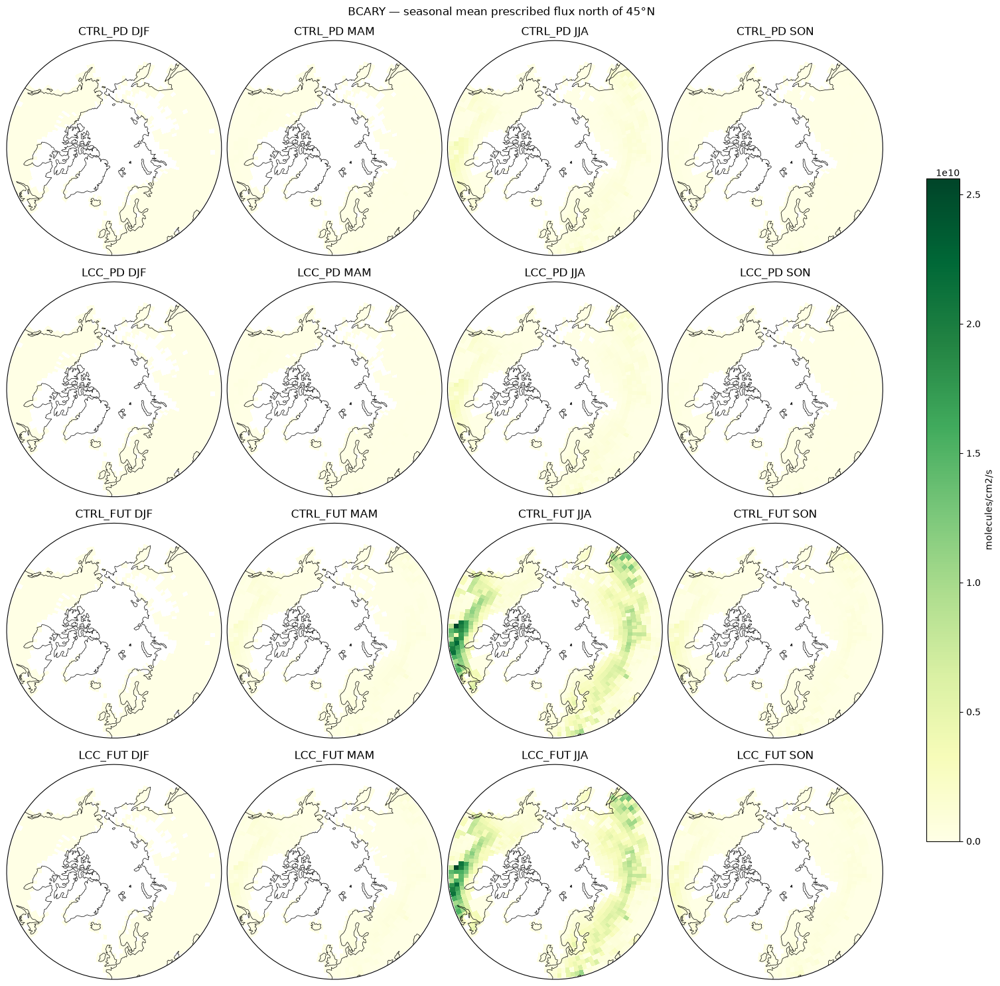

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

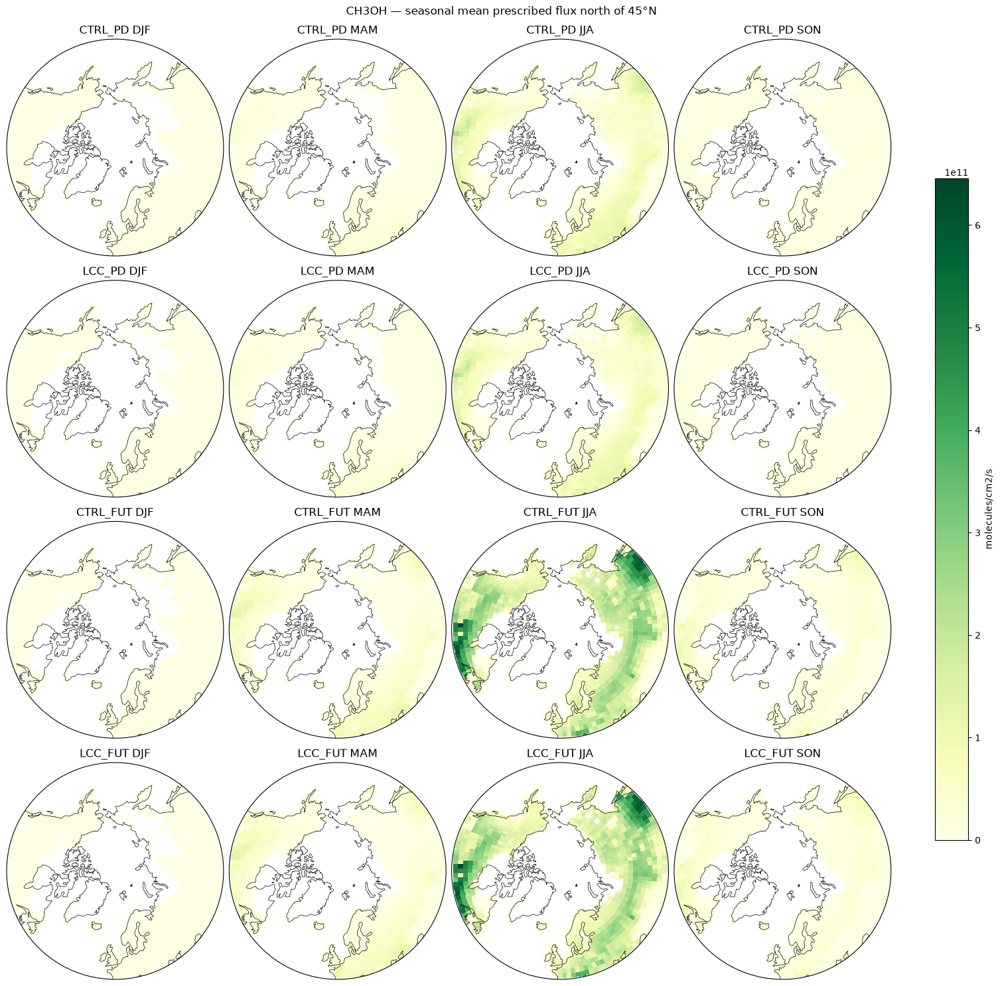

In [8]:
SEASONAL_SPECIES = ["SFISOP", "SFMTERP", "MEG_BCARY", "MEG_CH3OH"]
cmap = plt.get_cmap("YlGn").copy(); cmap.set_bad("white")   # zero flux (masked below) -> white
for var in SEASONAL_SPECIES:
    panels = {(src, s): seasonal[var, src][s].where(lat > 45, drop=True) for src in SOURCES for s in SEASONS}
    panels = {key: f.where(f > 0) for key, f in panels.items()}
    vmax = max(max(float(f.max()) for f in panels.values() if f.notnull().any()), 1e-30)
    fig, axes = plt.subplots(len(SOURCES), 4, figsize=(15, 3.7 * len(SOURCES)),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True)
    for ax, ((src, s), field) in zip(axes.flat, panels.items()):
        mesh = draw(ax, field, [-180, 180, 45, 90], cmap=cmap, vmin=0, vmax=vmax)
        ax.set_title(f"{src} {s}")
    fig.colorbar(mesh, ax=axes.ravel().tolist(), shrink=0.7, label=units[var])
    fig.suptitle(f"{OUTPUT_VAR_NAME[var]} — seasonal mean prescribed flux north of 45°N")
    save(fig, f"seasonal_maps_45N_{var}")